In [1]:
import pandas as pd
import numpy as np

In [2]:
import plotly.express as px
import matplotlib
import matplotlib.pyplot as plt 
import seaborn as sns
%matplotlib inline

ANALYSIS OF DATA USING NUMPY,PANDAS,MATPLOTLIB, AND SEABORN

In [ ]:
sns.set_style('darkgrid')
matplotlib.rcParams['font.size']=14
matplotlib.rcParams['figure.figsize']=(10,6)
matplotlib.rcParams['figure.facecolor']='#00000000'

In [4]:
medical_df=pd.read_csv("medical-charges.csv")

In [5]:
medical_df.age.describe()

count    1338.000000
mean       39.207025
std        14.049960
min        18.000000
25%        27.000000
50%        39.000000
75%        51.000000
max        64.000000
Name: age, dtype: float64

In [6]:
fig=px.histogram(medical_df,x='age',
                 marginal='box',
                 nbins=47,
                 title='Distribution of Age')
fig.update_layout(bargap=0.1)

In [7]:
fig = px.histogram(medical_df,x='charges',color='smoker',
                   color_discrete_sequence=['green','grey'],
                   title='Annual Medical Charge')
fig.update_layout(bargap=0.1)
fig.show()

In [8]:
fig = px.histogram(medical_df,x='charges',color='region',
                   color_discrete_sequence=['green','grey','blue','black'],
                   title='Annual Medical Charge')
fig.update_layout(bargap=0.1)
fig.show()

In [9]:
medical_df.smoker.value_counts()

smoker
no     1064
yes     274
Name: count, dtype: int64

In [10]:
fig = px.histogram(medical_df,x='smoker',color='sex',
                   color_discrete_sequence=['green','grey'],
                   title='Smoker data')
fig.update_layout(bargap=0.1)
fig.show()

In [11]:
fig =px.scatter(medical_df,
                x='age',y='charges',
                color='smoker',
                opacity=0.8,
                hover_data=['sex'],
                title='Age vs Charges')
fig.update_traces(marker_size=5)
fig.show()

In [12]:
def corrC(x,y):
    n=len(x)
    numerator= n*(np.sum(x*y))-np.sum(x)*np.sum(y)
    denominator = np.sqrt((n*np.sum(x**2)-np.sum(x)**2)*(n*np.sum(y**2)-np.sum(y)**2))
    return numerator/denominator

In [13]:
cols = medical_df.select_dtypes(include='number').columns
for col1 in cols:
    for col2 in cols:
        if col1 != col2:
            print(col1, col2, corrC(medical_df[col1], medical_df[col2]))

age bmi 0.10927188154853505
age children 0.042468998558849475
age charges 0.2990081933306475
bmi age 0.10927188154853505
bmi children 0.012758900820673881
bmi charges 0.19834096883362778
children age 0.042468998558849475
children bmi 0.012758900820673881
children charges 0.06799822684790473
charges age 0.2990081933306475
charges bmi 0.19834096883362778
charges children 0.06799822684790473


In [14]:
smoker_values = {'no':0,'yes':1}
smoker_numeric= medical_df.smoker.map(smoker_values)
smoker_numeric

0       1
1       0
2       0
3       0
4       0
       ..
1333    0
1334    0
1335    0
1336    0
1337    1
Name: smoker, Length: 1338, dtype: int64

In [15]:
corrC(smoker_numeric,medical_df.charges)

np.float64(0.7872514304984775)

In [16]:
medical_df.select_dtypes(include='number').corr()

,age,bmi,children,charges
age,1.000000,0.109272,0.042469,0.299008
bmi,0.109272,1.000000,0.012759,0.198341
children,0.042469,0.012759,1.000000,0.067998
charges,0.299008,0.198341,0.067998,1.000000


Text(0.5, 1.0, 'HeadMap of correlations')

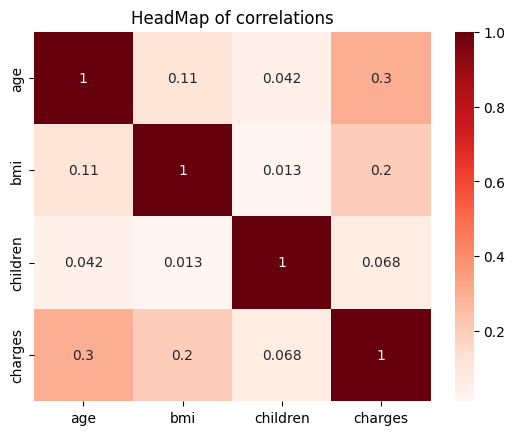

In [17]:
sns.heatmap(medical_df.select_dtypes(include='number').corr(),cmap='Reds',annot=True)
plt.title("HeadMap of correlations")

LINEAR REGRESSION MODEL

In [18]:
non_smoker_df = medical_df[medical_df.smoker=='no']

<Axes: title={'center': 'Age vs Charges for non-smokers'}, xlabel='age', ylabel='charges'>

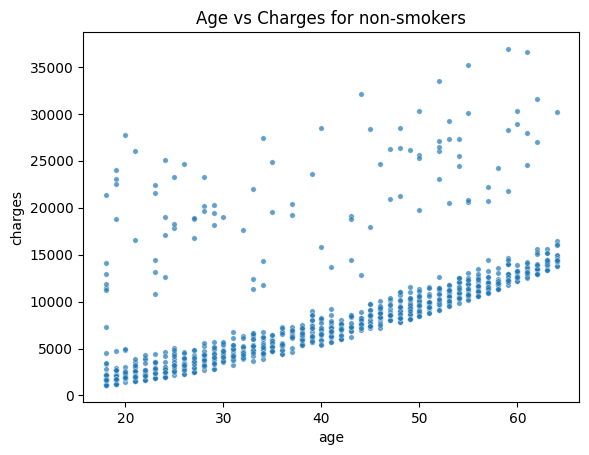

In [19]:
plt.title("Age vs Charges for non-smokers")
sns.scatterplot(data=non_smoker_df,x='age',y='charges',alpha=0.7,s=15)

In [20]:
def estimate_charges(age,w,b):
    return w*age+b

In [21]:
w=300
b=-2500
ages=non_smoker_df.age
estimated_charges=estimate_charges(ages,w,b)


In [22]:
# plt.plot(ages,estimate_charges,'r-')
# plt.xlabel('Age')
# plt.ylabel('Estimated Charges')

In [23]:
def try_parameters(w, b):
    ages = non_smoker_df.age
    target = non_smoker_df.charges
    predictions=estimate_charges(ages,w,b)    
    plt.plot(ages, estimated_charges, 'r', alpha=0.9)
    plt.scatter(ages, target, s=8,alpha=0.8)
    plt.xlabel('Age')
    plt.ylabel('Charges')
    plt.legend(['Estimate', 'Actual'])
    loss = rmse(target,predictions)
    print("RMSE Loss: ",loss)

In [24]:
targets=non_smoker_df.charges
predictions=estimate_charges

In [25]:
def rmse(targets,predictions):
    return np.sqrt(np.mean(np.square(targets-predictions)))

RMSE Loss:  4686.97290587829


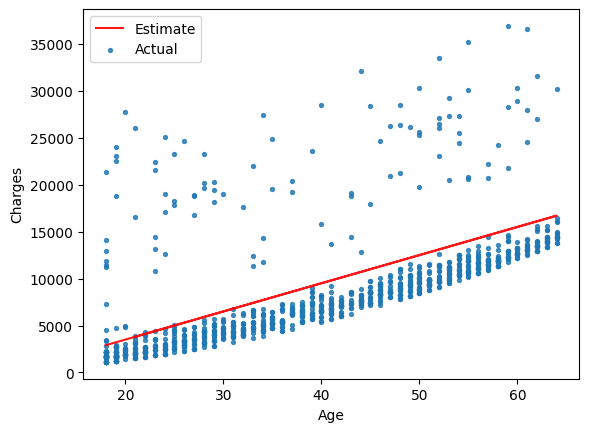

In [26]:
w=250
b=-1000
try_parameters(w,b)
targets=non_smoker_df['charges']
predicted=estimate_charges(non_smoker_df.age,w,b)

In [27]:

def find_best_rmse(ages, targets):
    best_rmse = float('inf')
    best_w = None
    best_b = None

    for w in np.arange(0, 1000, 1):
        for b in np.arange(-10000, 10000, 100):
            predicted = estimate_charges(ages, w, b)

            rmse = np.sqrt(np.mean((targets - predicted) ** 2))

            if rmse < best_rmse:
                best_rmse = rmse
                best_w = w
                best_b = b

    return best_w, best_b, best_rmse

In [28]:
# find_best_rmse(ages,targets)

In [29]:
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import SGDRegressor

In [30]:
model = LinearRegression()

In [31]:
inputs= non_smoker_df[['age']]
targets=non_smoker_df.charges
model.fit(inputs,targets)


LinearRegression()

In [32]:
predictions=model.predict(inputs)
predictions

array([2719.0598744 , 5391.54900271, 6727.79356686, ..., 2719.0598744 ,
       2719.0598744 , 3520.80661289])

In [33]:
rmse(targets,predictions)

np.float64(4662.505766636395)

In [34]:
model.coef_
model.intercept_

np.float64(-2091.420556565021)

RMSE Loss:  4662.505766636395


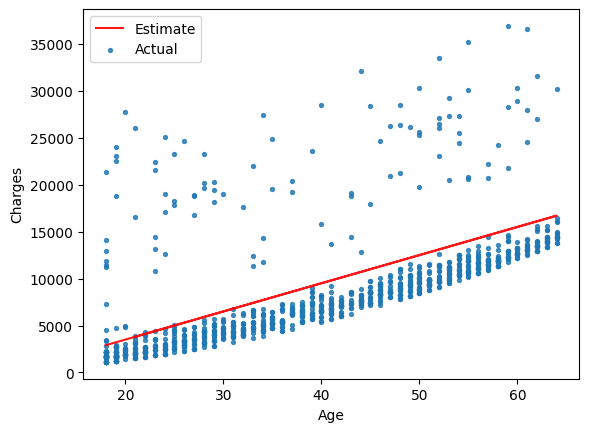

In [35]:
try_parameters(model.coef_,model.intercept_)

LINEAR REGRESSION WITH MULTIPLE FACTORS(uses multiple factors like, age, bmi...)
Here, Charges = W1*Age + W2* Bmi +b 

In [36]:
inputs, targets  = medical_df[['age','bmi','children',]],medical_df['charges']
model = LinearRegression().fit(inputs,targets)
predictions=model.predict(inputs)
loss = rmse(targets,predictions)
print('Loss: ',loss)

Loss:  11355.317901125973


/Users/sidharth/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/sidharth/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/sidharth/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
